<a href="https://colab.research.google.com/github/aadityapadghan06/ANALYSING-STUDENT-SPENDING-BEHAVIOUR-FROM-A-BANK-LEDGER/blob/main/Financial_Ledger_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **FINANCIAL LEDGER DATA ANALYSIS**

In [2]:
import os
import pandas as pd
import numpy as np

file_path = "/content/sample_data/Financial_Ledger_ September & October.xlsx"
df = pd.read_excel(file_path)

print (df.dtypes)
print (df.head())

Date            object
Particulars     object
Debit          float64
Credit         float64
Balance          int64
dtype: object
       Date     Particulars  Debit  Credit  Balance
0   14 Sept     Zagdu Singh    NaN  6325.0     7482
1   15 Sept          Petrol  260.0     NaN     7222
2   15 Sept      Food - CSB   80.0     NaN     7142
3   15 Sept           Books  250.0     NaN     6892
4  15 Sept   Rajesh Padghan    NaN   540.0     7432


In [3]:
df = pd.read_excel("/content/sample_data/Financial_Ledger_ September & October.xlsx", usecols = ["Particulars", "Debit", "Balance"])
print (df)

        Particulars  Debit  Balance
0       Zagdu Singh    NaN     7482
1            Petrol  260.0     7222
2        Food - CSB   80.0     7142
3             Books  250.0     6892
4    Rajesh Padghan    NaN     7432
..              ...    ...      ...
187  Mahendra Kumar  122.0     2736
188  Surendra Yadav  105.0     2631
189    Siddhi Singh  100.0     2531
190      Food - CSB  260.0     2271
191          Petrol  240.0     2031

[192 rows x 3 columns]


# **DATA CLEANING**

In [4]:
# Cell 1. Copy the data and standardise the columns
import pandas as pd
import numpy as np

# Load the raw dataset first to define df_raw
df_raw = pd.read_excel("/content/sample_data/Financial_Ledger_ September & October.xlsx")

df = df_raw.copy()

# drop empty "Unnamed" columns that Excel adds
df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]

# consistent column names
df.columns = df.columns.str.strip().str.lower()

print(df.shape)
df.head()

(192, 5)


,date,particulars,debit,credit,balance
0,14 Sept,Zagdu Singh,NaN,6325.0,7482
1,15 Sept,Petrol,260.0,NaN,7222
2,15 Sept,Food - CSB,80.0,NaN,7142
3,15 Sept,Books,250.0,NaN,6892
4,15 Sept,Rajesh Padghan,NaN,540.0,7432


In [5]:
# Cell 2. Fix dates
def parse_date(x):
    # October rows are already real dates
    if hasattr(x, "year"):
        return pd.Timestamp(x)
    # September rows are text like "14 Sept" with no year
    s = str(x).strip().replace("Sept", "Sep")
    return pd.to_datetime(f"{s} 2026", format="%d %b %Y", errors="coerce")

df["date"] = df["date"].apply(parse_date)

print("Unparsed dates:", df["date"].isna().sum())
print("Range:", df["date"].min().date(), "to", df["date"].max().date())
print("Already in date order:", df["date"].is_monotonic_increasing)

Unparsed dates: 0
Range: 2026-09-14 to 2026-10-31
Already in date order: True


In [6]:
# Cell 3. Clean the text and numbers, and build a single signed amount
df["particulars"] = (df["particulars"].astype(str)
                       .str.strip()
                       .str.replace(r"\s+", " ", regex=True))

df["debit"]  = df["debit"].fillna(0.0)
df["credit"] = df["credit"].fillna(0.0)

df["amount"]   = df["credit"] - df["debit"]          # + money in, - money out
df["txn_type"] = np.where(df["credit"] > 0, "Credit", "Debit")

df["month"]   = df["date"].dt.to_period("M").astype(str)
df["weekday"] = df["date"].dt.day_name()

df.groupby("txn_type")["amount"].agg(["count", "sum"])

,count,sum
txn_type,,
Credit,43,28982.00
Debit,149,-28173.36


In [7]:
# Cell 4. Reconcile the running balance
df["expected_balance"] = df["balance"].shift(1) + df["amount"]
df["bal_diff"] = (df["balance"] - df["expected_balance"]).round(2)

mismatch = df[df["bal_diff"].abs() > 1]
print(f"{len(mismatch)} rows don't reconcile")
mismatch[["date", "particulars", "debit", "credit", "balance", "expected_balance", "bal_diff"]]

6 rows don't reconcile


,date,particulars,debit,credit,balance,expected_balance,bal_diff
10,2026-09-19,Uber,483.33,0.0,5807,5803.67,3.33
11,2026-09-20,Food - CSB,50.00,0.0,5754,5757.00,-3.00
145,2026-10-17,Rapido,107.00,0.0,3560,3540.00,20.00
146,2026-10-17,Swarg,95.00,0.0,3445,3465.00,-20.00
163,2026-10-22,Apple Payment,69.00,0.0,3292,3154.00,138.00
166,2026-10-24,Railways,29.00,0.0,2804,2873.00,-69.00


In [8]:
# Cell 5. Tag the funders

def classify_credit(row):
    if row["credit"] == 0:
        return "Not a credit"
    p = row["particulars"].lower()
    if "padghan" in p or "zagdu" in p:
        return "Funding"
    if p == "college":
        return "Fee refund (Zagdu Singh)"      # refund of money already spent, not income
    if p == "bank":
        return "Bank"
    return "Friend reimbursement"

df["credit_source"] = df.apply(classify_credit, axis=1)
df[df["credit"] > 0].groupby("credit_source")["credit"].agg(["count", "sum"])

,count,sum
credit_source,,
Bank,1,26.0
Fee refund (Zagdu Singh),1,10407.0
Friend reimbursement,31,4464.0
Funding,10,14085.0


In [9]:
# Cell 6. Save the cleaned data
df.to_csv("ledger_clean.csv", index=False)
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              192 non-null    datetime64[ns]
 1   particulars       192 non-null    object        
 2   debit             192 non-null    float64       
 3   credit            192 non-null    float64       
 4   balance           192 non-null    int64         
 5   amount            192 non-null    float64       
 6   txn_type          192 non-null    object        
 7   month             192 non-null    object        
 8   weekday           192 non-null    object        
 9   expected_balance  191 non-null    float64       
 10  bal_diff          191 non-null    float64       
 11  credit_source     192 non-null    object        
dtypes: datetime64[ns](1), float64(5), int64(1), object(5)
memory usage: 18.1+ KB


,date,particulars,debit,credit,balance,amount,txn_type,month,weekday,expected_balance,bal_diff,credit_source
0,2026-09-14,Zagdu Singh,0.0,6325.0,7482,6325.0,Credit,2026-09,Monday,NaN,NaN,Funding
1,2026-09-15,Petrol,260.0,0.0,7222,-260.0,Debit,2026-09,Tuesday,7222.0,0.0,Not a credit
2,2026-09-15,Food - CSB,80.0,0.0,7142,-80.0,Debit,2026-09,Tuesday,7142.0,0.0,Not a credit
3,2026-09-15,Books,250.0,0.0,6892,-250.0,Debit,2026-09,Tuesday,6892.0,0.0,Not a credit
4,2026-09-15,Rajesh Padghan,0.0,540.0,7432,540.0,Credit,2026-09,Tuesday,7432.0,0.0,Funding


In [10]:
# Cell 7. The rule table and the categoriser

import re

# order matters: the first matching rule wins
RULES = [
    ("Savings & Investments",  r"^sip$"),
    ("Subscriptions",          r"netflix|apple payment"),
    ("Bank charges",           r"qtrly|^bank$"),
    ("Education",              r"^books$|parking at college|^college$|pendrive"),
    ("Transport - Essential",  r"petrol|metro|railways|parking at sky"),
    ("Transport - Cab/Auto",   r"uber|rapido"),
    ("Eating Out",             r"^food|cold drinks|sando|chai|sweets"),
    ("Groceries & Daily Needs",r"general store|blinkit|mart|chemist|pharma|medical"),
    ("Shopping & Fashion",     r"jacket|footwear|bangles|trazer|waffle tee|electronic"),
]
FALLBACK = "Payments to Individuals"

def categorise(row):
    if row["debit"] == 0:
        return "Income / Credit"
    p = row["particulars"].lower()
    for category, pattern in RULES:
        if re.search(pattern, p):
            return category
    return FALLBACK

df["category"] = df.apply(categorise, axis=1)

In [11]:
# Cell 8. Check the result
spend = df[df["debit"] > 0]

summary = (spend.groupby("category")["debit"]
                .agg(count="count", total="sum")
                .sort_values("total", ascending=False))
summary["share_%"] = (summary["total"] / summary["total"].sum() * 100).round(1)
summary

,count,total,share_%
category,,,
Eating Out,45,9584.00,34.0
Payments to Individuals,19,3675.00,13.0
Shopping & Fashion,7,3170.00,11.3
Transport - Cab/Auto,20,3005.26,10.7
Transport - Essential,23,2763.10,9.8
Education,9,2714.00,9.6
Groceries & Daily Needs,19,1737.00,6.2
Savings & Investments,1,1000.00,3.5
Subscriptions,5,455.00,1.6


# **DATA VISUALIZATION**

# **EATING OUT**

In [12]:
eat = df[df["category"] == "Eating Out"].copy()

# strip the "Food - " prefix to get a venue name
eat["venue"] = (eat["particulars"]
                .str.replace(r"^food\s*-?\s*", "", case=False, regex=True)
                .str.strip().str.title()
                .replace("", "Unspecified"))
eat["venue"] = eat["venue"].replace({"Csb": "CSB", "Mcd": "McDonald's", "Nbc": "NBC"})

total = eat["debit"].sum()
print(f"Eating out: ₹{total:,.0f} across {len(eat)} orders, avg ₹{eat['debit'].mean():.0f} each")

Eating out: ₹9,584 across 45 orders, avg ₹213 each


In [13]:
venue = (eat.groupby("venue")["debit"]
            .agg(visits="count", total="sum", avg="mean")
            .sort_values("total", ascending=False))
venue["share_%"] = (venue["total"] / total * 100).round(1)
venue["cum_%"]   = venue["share_%"].cumsum().round(1)
venue.head(12).round(1)

,visits,total,avg,share_%,cum_%
venue,,,,,
CSB,16,1555.0,97.2,16.2,16.2
Wonton Point,1,971.0,971.0,10.1,26.3
Jimis Burger,1,858.0,858.0,9.0,35.3
Veg Treat,1,667.0,667.0,7.0,42.3
Konark,1,588.0,588.0,6.1,48.4
Sando At Village,1,580.0,580.0,6.1,54.5
McDonald's,2,516.0,258.0,5.4,59.9
Saybeen,1,420.0,420.0,4.4,64.3
Pizza Hut,1,397.0,397.0,4.1,68.4


In [14]:
def ticket_tier(x):
    if x < 100:  return "Small (<₹100)"
    if x < 300:  return "Medium (₹100-299)"
    return "Large (₹300+)"

eat["ticket"] = eat["debit"].apply(ticket_tier)
tiers = eat.groupby("ticket")["debit"].agg(orders="count", total="sum")
tiers["share_%"] = (tiers["total"] / total * 100).round(1)
tiers.loc[["Small (<₹100)", "Medium (₹100-299)", "Large (₹300+)"]]

,orders,total,share_%
ticket,,,
Small (<₹100),22,1490.0,15.5
Medium (₹100-299),12,2193.0,22.9
Large (₹300+),11,5901.0,61.6


In [15]:
# fair monthly comparison: Sept has only 17 days of data (14-30 Sept)
days_in_data = df.groupby("month")["date"].agg(lambda s: (s.max() - s.min()).days + 1)

monthly = eat.groupby("month")["debit"].agg(orders="count", total="sum")
monthly["days"] = days_in_data
monthly["per_day"] = (monthly["total"] / monthly["days"]).round(1)
print(monthly)

order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday = eat.groupby("weekday")["debit"].agg(orders="count", total="sum").reindex(order)
weekday

         orders   total  days  per_day
month                                 
2026-09      18  3786.0    17    222.7
2026-10      27  5798.0    31    187.0


,orders,total
weekday,,
Monday,6,822.0
Tuesday,6,1098.0
Wednesday,10,1569.0
Thursday,7,1571.0
Friday,2,648.0
Saturday,7,2420.0
Sunday,7,1456.0


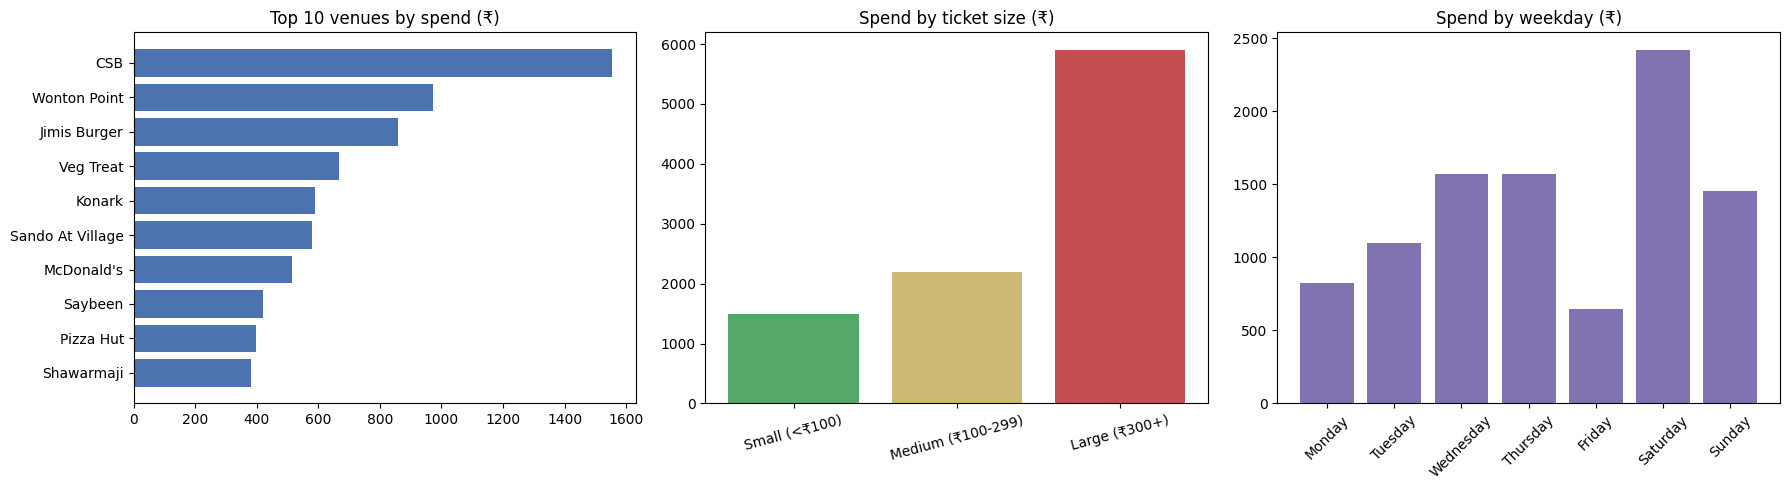

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

top = venue.head(10).sort_values("total")
ax[0].barh(top.index, top["total"], color="#4C72B0")
ax[0].set_title("Top 10 venues by spend (₹)")

t = tiers.loc[["Small (<₹100)", "Medium (₹100-299)", "Large (₹300+)"]]
ax[1].bar(t.index, t["total"], color=["#55A868", "#CCB974", "#C44E52"])
ax[1].set_title("Spend by ticket size (₹)")
ax[1].tick_params(axis="x", rotation=15)

ax[2].bar(weekday.index, weekday["total"], color="#8172B2")
ax[2].set_title("Spend by weekday (₹)")
ax[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# **TRANSPORT**

In [17]:
# transport categories + parking (college parking sits under Education in Phase 2,
# but it's vehicle-related, so we pull it in here)
trans = df[df["category"].str.startswith("Transport") |
           df["particulars"].str.contains("parking", case=False)].copy()

def get_mode(p):
    p = p.lower()
    if "uber" in p:    return "Uber"
    if "rapido" in p:  return "Rapido"
    if "metro" in p:   return "Metro"
    if "railway" in p: return "Railways"
    if "petrol" in p:  return "Petrol"
    if "parking" in p: return "Parking"
    return "Other"

# note: the column is "travel_mode", because "mode" clashes with a pandas method
trans["travel_mode"] = trans["particulars"].apply(get_mode)
trans["type"] = trans["travel_mode"].map({
    "Uber": "Cab/Auto", "Rapido": "Cab/Auto",
    "Metro": "Public",  "Railways": "Public",
    "Petrol": "Own vehicle", "Parking": "Own vehicle"})

total = trans["debit"].sum()
print(f"Transport: ₹{total:,.0f} across {len(trans)} payments")

Transport: ₹5,878 across 46 payments


In [18]:
by_mode = (trans.groupby("travel_mode")["debit"]
                .agg(trips="count", total="sum", avg="mean", max="max")
                .sort_values("total", ascending=False))
by_mode["share_%"] = (by_mode["total"] / total * 100).round(1)
display(by_mode.round(1))

by_type = trans.groupby("type")["debit"].agg(trips="count", total="sum")
by_type["share_%"] = (by_type["total"] / total * 100).round(1)
by_type

,trips,total,avg,max,share_%
travel_mode,,,,,
Petrol,11,2050.0,186.4,260.0,34.9
Uber,7,1942.3,277.5,483.3,33.0
Rapido,13,1063.0,81.8,174.0,18.1
Metro,7,540.0,77.1,140.0,9.2
Parking,5,210.0,42.0,50.0,3.6
Railways,3,73.1,24.4,29.1,1.2


,trips,total,share_%
type,,,
Cab/Auto,20,3005.26,51.1
Own vehicle,16,2260.00,38.4
Public,10,613.10,10.4


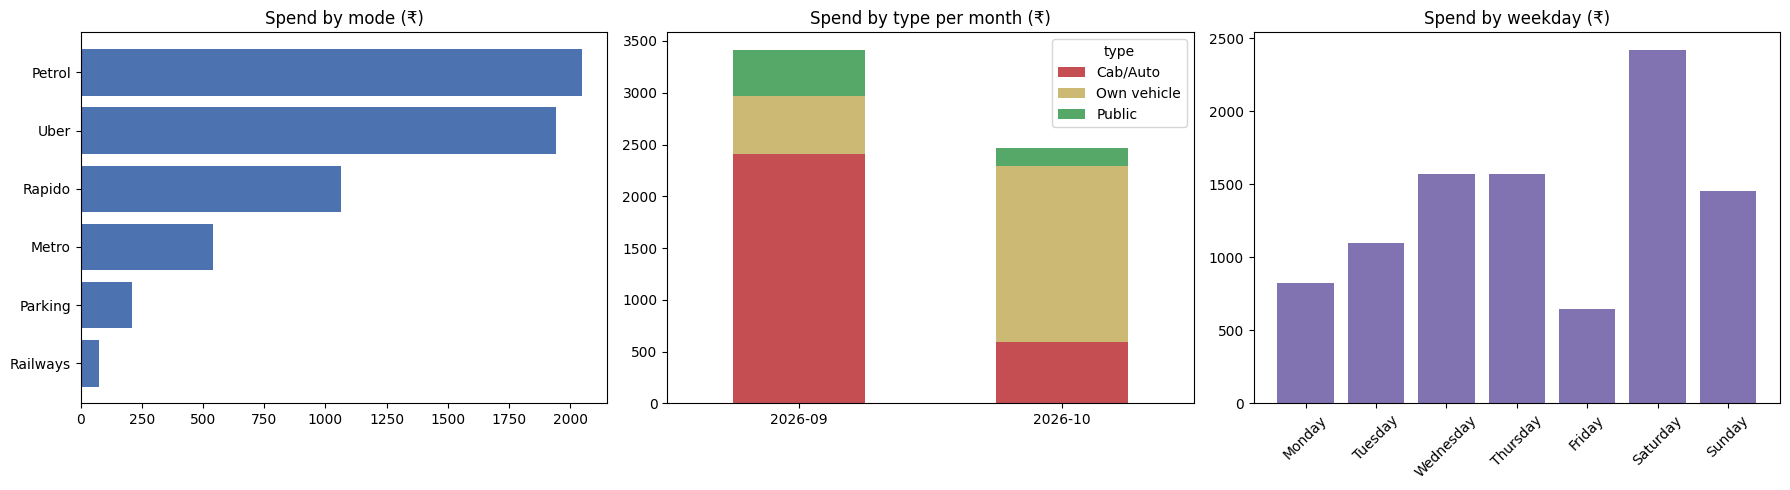

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# 1. Spend by mode
bm = by_mode.sort_values("total")
ax[0].barh(bm.index, bm["total"], color="#4C72B0")
ax[0].set_title("Spend by mode (₹)")

# 2. Spend by type per month (Fixed by creating a monthly pivot from the trans dataframe)
monthly_trans = trans.pivot_table(
    index="month",
    columns="type",
    values="debit",
    aggfunc="sum"
).fillna(0)

monthly_trans[["Cab/Auto", "Own vehicle", "Public"]].plot(
    kind="bar", stacked=True, ax=ax[1],
    color=["#C44E52", "#CCB974", "#55A868"]
)
ax[1].set_title("Spend by type per month (₹)")
ax[1].tick_params(axis="x", rotation=0)
ax[1].set_xlabel("")

# 3. Spend by weekday
ax[2].bar(weekday.index, weekday["total"], color="#8172B2")
ax[2].set_title("Spend by weekday (₹)")
ax[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# **CONFUSION MATRIX**

In [20]:
df["venue"] = df["particulars"].str.lower()

def need_want(r):
    c, p, d = r["category"], r["venue"], r["debit"]
    if d == 0:                                   return "Not spending"
    if c == "Savings & Investments":             return "Savings"
    if c in ("Education", "Groceries & Daily Needs",
             "Bank charges", "Transport - Essential"):   return "Need"
    if c == "Eating Out":                        # daily canteen food = need, restaurant meals = want
        return "Need" if (d < 100 or "csb" in p or "college" in p) else "Want"
    if c == "Transport - Cab/Auto":              # short rides = need, rides of ₹200+ = want
        return "Need" if d < 200 else "Want"
    if c in ("Subscriptions", "Shopping & Fashion"):     return "Want"
    return "Unclear"                             # payments to individuals we can't identify

df["nature"] = df.apply(need_want, axis=1)

spend = df[df["debit"] > 0]
total = spend["debit"].sum()
split = spend.groupby("nature")["debit"].agg(txns="count", total="sum")
split["share_%"] = (split["total"] / total * 100).round(1)
split

,txns,total,share_%
nature,,,
Need,94,11171.10,39.7
Savings,1,1000.00,3.5
Unclear,19,3675.00,13.0
Want,35,12327.26,43.8


In [21]:
spend.pivot_table(index="category", columns="nature", values="debit",
                  aggfunc="sum", fill_value=0, margins=True).round(0)

nature,Need,Savings,Unclear,Want,All
category,,,,,
Bank charges,70.0,0.0,0.0,0.0,70.0
Eating Out,2310.0,0.0,0.0,7274.0,9584.0
Education,2714.0,0.0,0.0,0.0,2714.0
Groceries & Daily Needs,1737.0,0.0,0.0,0.0,1737.0
Payments to Individuals,0.0,0.0,3675.0,0.0,3675.0
Savings & Investments,0.0,1000.0,0.0,0.0,1000.0
Shopping & Fashion,0.0,0.0,0.0,3170.0,3170.0
Subscriptions,0.0,0.0,0.0,455.0,455.0
Transport - Cab/Auto,1577.0,0.0,0.0,1428.0,3005.0


In [22]:
days = (df["date"].max() - df["date"].min()).days + 1
wants = spend[spend["nature"] == "Want"]
wants_by_cat = wants.groupby("category")["debit"].sum()

# how much of each Want category you commit to cutting
cuts = {"Eating Out": 0.40, "Shopping & Fashion": 0.50,
        "Transport - Cab/Auto": 0.60, "Subscriptions": 0.25}

plan = pd.DataFrame({"current": wants_by_cat})
plan["cut_%"]  = [cuts.get(c, 0) * 100 for c in plan.index]
plan["saving"] = (plan["current"] * plan["cut_%"] / 100).round(0)
plan["saving_per_month"] = (plan["saving"] / days * 30).round(0)
display(plan)

print(f"Total saving over {days} days: ₹{plan['saving'].sum():,.0f}")
print(f"Per month: ₹{plan['saving_per_month'].sum():,.0f}")
print(f"Wants as share of spend: {wants['debit'].sum()/total:.0%} → "
      f"{(wants['debit'].sum()-plan['saving'].sum())/(total-plan['saving'].sum()):.0%}")

,current,cut_%,saving,saving_per_month
category,,,,
Eating Out,7274.00,40.0,2910.0,1819.0
Shopping & Fashion,3170.00,50.0,1585.0,991.0
Subscriptions,455.00,25.0,114.0,71.0
Transport - Cab/Auto,1428.26,60.0,857.0,536.0


Total saving over 48 days: ₹5,466
Per month: ₹3,417
Wants as share of spend: 44% → 30%


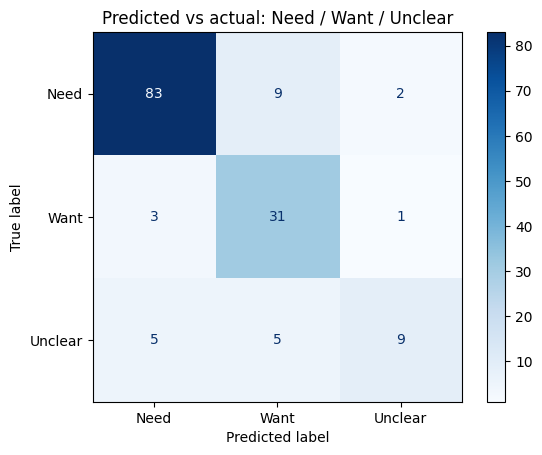

              precision    recall  f1-score   support

        Need       0.91      0.88      0.90        94
        Want       0.69      0.89      0.78        35
     Unclear       0.75      0.47      0.58        19

    accuracy                           0.83       148
   macro avg       0.78      0.75      0.75       148
weighted avg       0.84      0.83      0.83       148



In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# the single SIP row is dropped: one example can't be cross-validated
ml = spend[spend["nature"].isin(["Need", "Want", "Unclear"])].copy()
ml["log_amt"] = np.log1p(ml["debit"])

X = ml[["particulars", "log_amt", "weekday"]]
y = ml["nature"]

pre = ColumnTransformer([
    ("txt", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4)), "particulars"),
    ("amt", StandardScaler(), ["log_amt"]),
    ("day", OneHotEncoder(handle_unknown="ignore"), ["weekday"]),
])
model = Pipeline([("pre", pre),
                  ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])

# every prediction is made on rows the model has not seen (5-fold cross-validation)
cv   = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pred = cross_val_predict(model, X, y, cv=cv)

labels = ["Need", "Want", "Unclear"]
cm = confusion_matrix(y, pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title("Predicted vs actual: Need / Want / Unclear")
plt.show()

print(classification_report(y, pred, labels=labels, zero_division=0))

# **FUNDING**

MONEY IN BY SOURCE
                          entries    total
source                                    
Bank                            1     26.0
Fee refund (Zagdu Singh)        1  10407.0
Friend reimbursement           31   4464.0
Funding                        10  14085.0 

FUNDING BY PERSON
                 transfers   total  largest  share_%
particulars                                         
Zagdu Singh              1  6325.0   6325.0     44.9
Atharva Padghan          6  5720.0   2500.0     40.6
Rajesh Padghan           2  1040.0    540.0      7.4
Ashwini Padghan          1  1000.0   1000.0      7.1
Total funding: 14,085
Padghan family: 7,760 (55.1%) in 9 transfers
Zagdu Singh incl. fee refund: 16,732

FUNDING TIMELINE
      date     particulars  credit  running_total
2026-09-14     Zagdu Singh  6325.0         6325.0
2026-09-15  Rajesh Padghan   540.0         6865.0
2026-10-03 Atharva Padghan   200.0         7065.0
2026-10-10 Atharva Padghan  1500.0         8565.0
2026-10-20 At

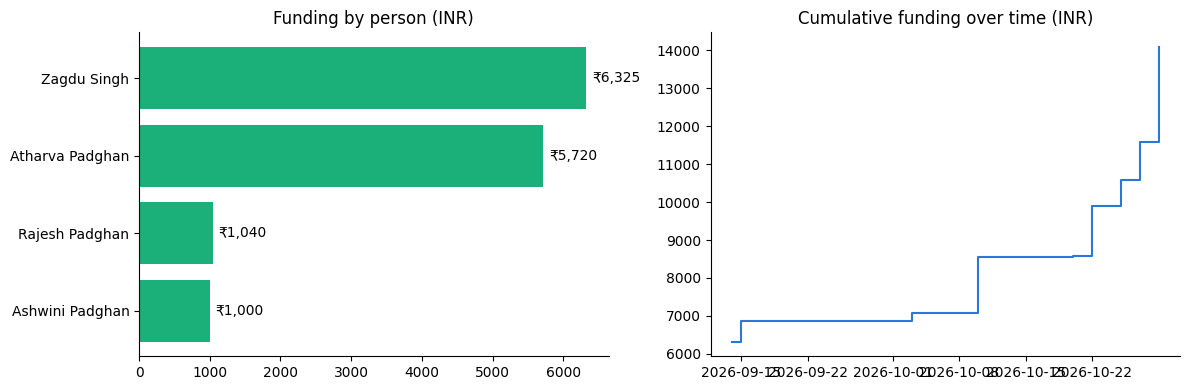

In [26]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Fixed: Use the correct file path directly instead of reading system arguments from sys.argv
FILE = "/content/sample_data/Financial_Ledger_ September & October.xlsx"

# --- load and clean the columns the funding analysis needs ---
df = pd.read_excel(FILE)
df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]
df.columns = df.columns.str.strip().str.lower()
df["particulars"] = df["particulars"].astype(str).str.strip()
df["credit"] = df["credit"].fillna(0.0)

def parse_date(x):
    if hasattr(x, "year"):
        return pd.Timestamp(x)
    # Fixed syntax error: removed backslashes from inside the f-string curly braces
    return pd.to_datetime(f"{str(x).strip().replace('Sept', 'Sep')} 2026", format="%d %b %Y", errors="coerce")
df["date"] = df["date"].apply(parse_date)

# --- tag every credit by source ---
def credit_source(row):
    p = row["particulars"].lower()
    if "padghan" in p or "zagdu" in p:
        return "Funding"
    if p == "college":
        return "Fee refund (Zagdu Singh)"      # refund of a fee paid outside the ledger, not income
    if p == "bank":
        return "Bank"
    return "Friend reimbursement"

credits = df[df["credit"] > 0].copy()
credits["source"] = credits.apply(credit_source, axis=1)

# 1) all money in, by source type
print("MONEY IN BY SOURCE")
print(credits.groupby("source")["credit"].agg(entries="count", total="sum"), "\n")

# 2) funding by person
funding = credits[credits["source"] == "Funding"]
by_person = (funding.groupby("particulars")["credit"]
             .agg(transfers="count", total="sum", largest="max")
             .sort_values("total", ascending=False))
by_person["share_%"] = (by_person["total"] / by_person["total"].sum() * 100).round(1)
print("FUNDING BY PERSON")
print(by_person)
print(f"Total funding: {funding['credit'].sum():,.0f}")

# 3) Padghan family vs Zagdu Singh
is_padghan = funding["particulars"].str.contains("padghan", case=False)
print(f"Padghan family: {funding[is_padghan]['credit'].sum():,.0f} "
      f"({funding[is_padghan]['credit'].sum() / funding['credit'].sum():.1%}) in {is_padghan.sum()} transfers")
zagdu_refund = credits[credits["source"].str.startswith("Fee")]["credit"].sum()
zagdu_total = funding[~is_padghan]['credit'].sum() + zagdu_refund
print(f"Zagdu Singh incl. fee refund: {zagdu_total:,.0f}\n")

# 4) every funding transfer in date order, with running total
timeline = funding[["date", "particulars", "credit"]].sort_values("date").copy()
timeline["running_total"] = timeline["credit"].cumsum()
print("FUNDING TIMELINE")
print(timeline.to_string(index=False), "\n")

# 5) funding by month
print("FUNDING BY MONTH")
print(funding.groupby(funding["date"].dt.to_period("M"))["credit"].agg(transfers="count", total="sum"))

# 6) chart
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bp = by_person.sort_values("total")
ax[0].barh(bp.index, bp["total"], color="#1baf7a")
for i, v in enumerate(bp["total"]):
    ax[0].text(v + 80, i, f"₹{v:,.0f}", va="center")
ax[0].set_title("Funding by person (INR)")
ax[1].step(timeline["date"], timeline["running_total"], where="post", color="#2a78d6")
ax[1].set_title("Cumulative funding over time (INR)")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("funding.png", dpi=150)
plt.show()